![Banner](../images/09_08_banner_rs_super_resolution.png)


# Landsat 8, Sentinel-2, PlanetScope, and high-resolution imagery

This tutorial brings the supplied four products into one **multi-sensor comparison** over a shared rural window.


## Overview

Landsat 8 Collection 2 Level-2 (30 m, July 9, 2019) is paired with Sentinel-2A Level-2A (10 m, July 8) for one direct experiment. PlanetScope PSScene (3 m, July 14) is separately paired with the high-resolution 0.6 m image whose filename is dated July 14. These are **two independent pairwise experiments**, not a chain: we do not feed a super-resolved Landsat image into the PlanetScope model, because doing so compounds model errors and invented detail.

The first experiment trains a four-band EDSR-style model from Landsat 30 m to Sentinel-2 10 m (blue, green, red, NIR) and compares it with classical interpolation on spatially held-out Sentinel-2 pixels. The second trains PlanetScope 3 m to high-resolution 0.6 m imagery on spatially held-out patches. PlanetScope's AOI file has generic band names, so its blue/green/red/NIR order is assumed. The high-resolution image is also generically labeled; its RGB/NIR order is assumed to be red/green/blue/NIR and reordered. PlanetScope integer values are scaled by 0.0001, and high-resolution byte values are divided by 255, then adjusted per band using a train-only linear calibration. These are explicit assumptions; verify source metadata before scientific interpretation.

The two reference pairs differ in date. Landsat and Sentinel-2 are one day apart. PlanetScope's original metadata confirms July 14, 2019; the HR filename is dated July 14 but its supplied sidecar does not confirm the capture time or sensor. Their calibration, bandpass, and sub-pixel registration are not guaranteed. Each output is a model-derived estimate on a finer grid-not a native fine-resolution Landsat or PlanetScope product.


## Workflow and GeoLattice APIs

1. Read the Landsat 8, Sentinel-2, PlanetScope and HR rasters with `geolattice.rsense.read` and inspect their acquisition metadata.
2. Select a shared 1.5 km window from the PlanetScope AOI, reproject the Landsat/Sentinel pair into its map CRS, and align each pair to exact output grids.
3. Train/evaluate Landsat → Sentinel-2 at ×3 using masks and spatial holdout patches.
4. Independently train/evaluate PlanetScope → HR at ×5, calibrating HR to PlanetScope from training regions only.
5. Compare the four observed scenes and write pairwise outputs as georeferenced COGs with `geolattice.rsense.write`.

GeoLattice handles raster I/O, reprojection, resampling, model construction, training, and tiled inference. The neural sections require PyTorch (`pip install "geolattice[rsense-dl]"`).


### Imports, paths, and experiment controls

This cell sets the dataset paths, channel order, study-window location, model patch sizes, and explicit radiometric assumptions. The selected PlanetScope window is 500×500 pixels at 3 m (1.5 km square); it is small enough to also compare with the 0.6 m HR raster without loading that large raster in full. `SEED` makes the spatial split and training initialization repeatable.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
from pathlib import Path  # file paths
import json  # read metadata JSON files
import os  # environment variables and CPU count
import sys  # Python import path

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import torch  # PyTorch: the neural super-resolution models
import xarray as xr  # labelled arrays and result tables
from rasterio.enums import Resampling  # resampling methods
from scipy.ndimage import distance_transform_edt  # distance to the nearest valid pixel (gap filling)
from torch.utils.data import DataLoader, TensorDataset  # feed patches to PyTorch in batches

# Prefer the working checkout's GeoLattice source when available.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense import super_resolution as sr  # super-resolution tools

if ROOT is None:  # not started inside the repository
    # stop with a clear message
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_08_image_super_resolution"
DATA_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_08_image_super_resolution"  # its data folder
LANDSAT_DIR = DATA_DIR / "Landsat8_20190709"  # Landsat 8 scene folder
SENTINEL_DIR = DATA_DIR / "Sentinel_2" / "L2A_T17TQH_20190708"  # Sentinel-2 scene folder
PLANET_DIR = DATA_DIR / "Planet" / "July_14_2019"  # PlanetScope folder
HR_DIR = DATA_DIR / "HR"  # high-resolution (HR) image folder
# Landsat surface reflectance, 30 m
LANDSAT_PATH = LANDSAT_DIR / "landsat8_20190709_surface_reflectance_30m.tif"
LANDSAT_MASK_PATH = LANDSAT_DIR / "clear_mask.tif"  # Landsat clear-sky mask
# Sentinel-2 surface reflectance, 10 m
SENTINEL_PATH = SENTINEL_DIR / "sentinel2_20190708_surface_reflectance_6band_10m.tif"
SENTINEL_MASK_PATH = SENTINEL_DIR / "clear_mask_10m.tif"  # Sentinel-2 clear-sky mask
PLANET_PATH = PLANET_DIR / "Planet_Rural_AOI_July_14_2019_NAD.tif"  # the PlanetScope image
# PlanetScope order manifest
PLANET_MANIFEST = PLANET_DIR / "Rural_July_14_2019_PSScene4Band_Explorer" / "manifest.json"
HR_PATH = HR_DIR / "HR_Rural_AOI_July_14.tif"  # the HR image
# Every input is a prepared clip of the study area kept in data/; there is no public download
# for these clips, so stop with a clear message when one is missing from the local drive.
INPUTS = [LANDSAT_PATH, LANDSAT_MASK_PATH, SENTINEL_PATH, SENTINEL_MASK_PATH, PLANET_PATH, HR_PATH]  # the input rasters of this notebook
missing = [str(p) for p in INPUTS if not p.exists()]  # inputs not found on the local drive
if missing:  # stop early with the list of missing files
    raise FileNotFoundError("Copy these files into the data folder first: " + ", ".join(missing))
print("Reading", len(INPUTS), "input rasters from", DATA_DIR)  # all inputs are local

# output folder (can be changed with an environment variable)
OUTPUT_DIR = Path(os.environ.get("GEOLATTICE_SR_OUTPUT", DATA_DIR / "super_resolution_outputs_all_sensors"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)  # create it if needed

BANDS = ["blue", "green", "red", "nir"]  # the four bands all sensors share
PLANET_DN_TO_REFLECTANCE = 1e-4  # Explicit assumption for the clipped PlanetScope values.
HR_DN_TO_UNIT_RANGE = 1 / 255  # Explicit assumption for the HR byte-like values.
PLANET_WINDOW_ROW, PLANET_WINDOW_COL = 500, 500  # top-left corner of the study window (PlanetScope pixels)
PLANET_WINDOW_SIZE = 500  # window size: 500 x 500 PlanetScope pixels (1.5 km)
SCALE_LANDSAT = 3  # 30 m Landsat -> 10 m: 3 times finer
SCALE_PLANET = 5  # 3 m PlanetScope -> 0.6 m: 5 times finer
PATCH_LANDSAT = 6  # Landsat patch size (pixels)
PATCH_PLANET = 16  # PlanetScope patch size (pixels)
SEED = 714  # random seed
torch.manual_seed(SEED)  # same initial weights on every run
torch.set_num_threads(min(4, os.cpu_count() or 1))  # use at most four CPU threads
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # use the GPU when available
print("GeoLattice checkout:", ROOT)  # repository path
print("PyTorch:", torch.__version__, "| device:", DEVICE)  # PyTorch version and device
print("Device:", DEVICE, "| output:", OUTPUT_DIR)  # device and output folder

GeoLattice checkout: /media/zia207/SSD/GitHub/GeoLattice
PyTorch: 2.10.0+cu128 | device: cuda
Device: cuda | output: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_all_sensors


### Read source rasters and acquisition metadata

Landsat stores seven bands; Sentinel-2 stores six. This workflow selects the four common blue/green/red/NIR channels. `rs.read` masks nodata and returns xarray data with CRS and affine coordinates. PlanetScope's scene ID and timestamp come from its Explorer manifest. The HR raster lacks a corresponding scene manifest, so its date is known only from the file naming, not an independently verified acquisition record.


In [2]:
landsat_metadata = json.loads((LANDSAT_DIR / "metadata.json").read_text())  # Landsat scene metadata
sentinel_metadata = json.loads((SENTINEL_DIR / "metadata.json").read_text())  # Sentinel-2 scene metadata
planet_manifest = json.loads(PLANET_MANIFEST.read_text())  # PlanetScope order manifest
planet_metadata_path = next(  # path of the scene's metadata JSON inside the order
    entry["path"] for entry in planet_manifest["files"]
    if entry["path"].endswith("20190714_142708_1049_metadata.json")
)
# the PlanetScope scene metadata
planet_item = json.loads((PLANET_DIR / "Rural_July_14_2019_PSScene4Band_Explorer" / planet_metadata_path).read_text())
planet_metadata = planet_item["properties"]  # its properties

landsat_all = rs.read(  # read the Landsat stack with band names
    LANDSAT_PATH,
    band_names=["coastal", "blue", "green", "red", "nir", "swir1", "swir2"],
)
landsat = landsat_all.sel(band=BANDS)  # keep the four shared bands
sentinel_all = rs.read(  # read the Sentinel-2 stack with band names
    SENTINEL_PATH,
    band_names=["blue", "green", "red", "nir", "swir1", "swir2"],
)
sentinel = sentinel_all.sel(band=BANDS)  # keep the four shared bands

# Generic Planet band labels are assigned the assumed PSScene 4-band order.
planet_all = rs.read(PLANET_PATH, band_names=BANDS)
hr_source = rs.read(  # read the HR image
    HR_PATH, chunks={"x": 2048, "y": 2048},
    band_names=["red", "green", "blue", "nir"],
)

print("Landsat:", landsat_metadata["scene_id"], landsat_metadata["acquired"])  # Landsat scene and date
print("Sentinel-2:", sentinel_metadata["scene_id"], sentinel_metadata["acquired"])  # Sentinel-2 scene and date
print("PlanetScope:", planet_item["id"], planet_metadata["acquired"],  # PlanetScope scene and date
      "reported GSD", planet_metadata["gsd"], "m")
# HR image (no date available)
print("HR image:", HR_PATH.name, "(acquisition timestamp unavailable in supplied sidecar)")
print("Shapes (Landsat, Sentinel, Planet, HR):",  # shapes of the four images
      landsat.shape, sentinel.shape, planet_all.shape, hr_source.shape)
print("CRS values:", landsat.rio.crs, sentinel.rio.crs,  # their CRS
      planet_all.rio.crs, hr_source.rio.crs)

Landsat: LC08_L2SP_017030_20190709_02_T1 2019-07-09T15:57:32.899443+00:00
Sentinel-2: S2A_MSIL2A_20190708T155911_R097_T17TQH_20201005T110153 2019-07-08T15:59:11.024000+00:00
PlanetScope: 20190714_142708_1049 2019-07-14T14:27:08.594337Z reported GSD 3.6 m
HR image: HR_Rural_AOI_July_14.tif (acquisition timestamp unavailable in supplied sidecar)
Shapes (Landsat, Sentinel, Planet, HR): (4, 203, 189) (4, 609, 567) (4, 2153, 2022) (4, 10761, 10106)
CRS values: EPSG:32617 EPSG:32617 EPSG:26918 EPSG:26918


### Define one study window and align the Landsat/Sentinel pair

The four source files use two UTM CRS definitions. We select a 500×500 PlanetScope window in EPSG:26918, reproject the Landsat and Sentinel data to that CRS, and clip Landsat to the window. GeoLattice `upsample` defines a matching 10 m output grid at exactly ×3. Sentinel-2 is aligned to that grid with bilinear reprojection. This produces a common four-band Landsat/Sentinel pair; it does not harmonize their spectral response or remove date-dependent land-cover change.


In [3]:
planet_window_dn = planet_all.isel(  # the PlanetScope study window
    y=slice(PLANET_WINDOW_ROW, PLANET_WINDOW_ROW + PLANET_WINDOW_SIZE),
    x=slice(PLANET_WINDOW_COL, PLANET_WINDOW_COL + PLANET_WINDOW_SIZE),
)
# DN -> reflectance with the assumed scale factor
planet_low = planet_window_dn.astype("float32") * PLANET_DN_TO_REFLECTANCE
planet_values = np.asarray(planet_low.values, dtype="float32")  # as a float array
planet_valid = np.isfinite(planet_values).all(axis=0)  # finite in every band
window_bounds = planet_low.rio.bounds()  # extent of the window

landsat_projected = rs.reproject(  # Landsat reprojected to the PlanetScope CRS
    landsat, dst_crs=planet_low.rio.crs, resolution=30, resampling="bilinear"
)
landsat_window = landsat_projected.rio.clip_box(  # clipped to the window
    minx=window_bounds[0], miny=window_bounds[1],
    maxx=window_bounds[2], maxy=window_bounds[3],
)
# the 10 m target grid (bicubic template from Landsat)
landsat_10m_grid = sr.upsample(landsat_window, SCALE_LANDSAT, method="bicubic")

sentinel_projected = rs.reproject(  # Sentinel-2 reprojected to the same CRS
    sentinel, dst_crs=planet_low.rio.crs, resolution=10, resampling="bilinear"
)
sentinel_10m = sentinel_projected.rio.reproject_match(  # aligned exactly to the 10 m grid
    landsat_10m_grid, resampling=Resampling.bilinear
).assign_coords(band=BANDS)

print("Planet study window:", planet_low.shape, planet_low.rio.bounds())  # window shape and bounds
print("Landsat window:", landsat_window.shape, landsat_window.rio.bounds())  # Landsat window
print("Landsat target grid:", landsat_10m_grid.shape, landsat_10m_grid.rio.resolution())  # 10 m grid
print("Sentinel aligned:", sentinel_10m.shape,  # aligned Sentinel-2
      np.allclose(sentinel_10m.rio.transform(), landsat_10m_grid.rio.transform()))

Planet study window: (4, 500, 500) (257871.20228942018, 4745051.0456366595, 259371.20228942018, 4746551.0456366595)
Landsat window: (4, 51, 51) (257858.80185859374, 4745037.178518094, 259388.80185859374, 4746567.178518094)
Landsat target grid: (4, 153, 153) (10.0, -10.0)
Sentinel aligned: (4, 153, 153) True


### Align masks and make safe finite model inputs

The Landsat clear mask and Sentinel-2 clear mask are reprojected with nearest-neighbor sampling so class labels are not interpolated. The four-band data must also be finite. Temporary nearest-neighbor filling allows filters and model tiles to run across masked pixels; original validity masks continue to govern training, validation, and exports.


In [4]:
landsat_clear_source = rs.read(  # Landsat clear mask
    LANDSAT_MASK_PATH, band_names=["clear"]
).isel(band=0, drop=True)
sentinel_clear_source = rs.read(  # Sentinel-2 clear mask
    SENTINEL_MASK_PATH, band_names=["clear"]
).isel(band=0, drop=True)

landsat_mask_projected = rs.reproject(  # Landsat mask in the window CRS
    landsat_clear_source, dst_crs=planet_low.rio.crs,
    resolution=30, resampling="nearest",
)
landsat_clear_window = landsat_mask_projected.rio.reproject_match(  # aligned to the Landsat window
    landsat_window, resampling=Resampling.nearest
)
sentinel_mask_projected = rs.reproject(  # Sentinel-2 mask in the window CRS
    sentinel_clear_source, dst_crs=planet_low.rio.crs,
    resolution=10, resampling="nearest",
)
sentinel_clear_10m = sentinel_mask_projected.rio.reproject_match(  # aligned to the 10 m grid
    landsat_10m_grid, resampling=Resampling.nearest
)

landsat_values = np.asarray(landsat_window.values, dtype="float32")  # Landsat as a float array
sentinel_values = np.asarray(sentinel_10m.values, dtype="float32")  # Sentinel-2 as a float array
# clear and finite in every band
landsat_valid = (landsat_clear_window.values == 1) & np.isfinite(landsat_values).all(axis=0)
# the same for Sentinel-2
sentinel_valid = (sentinel_clear_10m.values == 1) & np.isfinite(sentinel_values).all(axis=0)

# PlanetScope 3 m data aligned to Sentinel's target grid for the scene overview.
planet_on_10m = planet_low.rio.reproject_match(
    landsat_10m_grid, resampling=Resampling.bilinear
).assign_coords(band=BANDS)
# PlanetScope on the 10 m grid as an array
planet_10m_values = np.asarray(planet_on_10m.values, dtype="float32")
planet_10m_valid = np.isfinite(planet_10m_values).all(axis=0)  # finite in every band

# an image with no valid pixels
if not landsat_valid.any() or not sentinel_valid.any() or not planet_valid.any():
    # stop with a clear message
    raise ValueError("A source scene has no valid pixels in the shared study window")
print("Valid fractions: Landsat", f"{landsat_valid.mean():.1%}",  # valid shares
      "Sentinel-2", f"{sentinel_valid.mean():.1%}",
      "PlanetScope", f"{planet_valid.mean():.1%}")

Valid fractions: Landsat 100.0% Sentinel-2 100.0% PlanetScope 100.0%


### Prepare the PlanetScope/HR comparison independently

PlanetScope's native grid is 3 m and the HR grid is 0.6 m, so a GeoLattice ×5 upsample creates the exact target coordinates. The HR raster is read lazily, reordered from assumed red/green/blue/NIR into blue/green/red/NIR, clipped to the selected 1.5 km square, and matched to the PlanetScope-derived target grid. This avoids loading the full 1.7 GB HR mosaic. The scene dates differ from the Landsat/Sentinel pair; the HR capture timestamp is not verified.


In [5]:
# the 0.6 m target grid (bicubic template from PlanetScope)
planet_60cm_grid = sr.upsample(planet_low, SCALE_PLANET, method="bicubic")

# Assumed HR source order is red, green, blue, NIR; map to PlanetScope B/G/R/NIR.
hr_bgrn = hr_source.isel(band=[2, 1, 0, 3]).assign_coords(band=BANDS)
hr_unit = hr_bgrn.astype("float32") * HR_DN_TO_UNIT_RANGE  # HR DN -> 0-1 range
xmin, ymin, xmax, ymax = planet_60cm_grid.rio.bounds()  # extent of the target grid
hr_subset = hr_unit.rio.clip_box(minx=xmin, miny=ymin, maxx=xmax, maxy=ymax)  # clip the HR image to it
hr_reference_da = hr_subset.rio.reproject_match(  # align it exactly to the target grid
    planet_60cm_grid, resampling=Resampling.bilinear
).assign_coords(band=BANDS).rio.write_nodata(np.nan)
hr_values = np.asarray(hr_reference_da.values, dtype="float32")  # as a float array
hr_valid = np.isfinite(hr_values).all(axis=0)  # finite in every band
valid_planet_hr = np.repeat(  # PlanetScope validity repeated onto the 0.6 m grid, combined with HR validity
    np.repeat(planet_valid, SCALE_PLANET, axis=0), SCALE_PLANET, axis=1
) & hr_valid

assert hr_reference_da.shape == planet_60cm_grid.shape  # same shape as the target grid
assert np.allclose(hr_reference_da.rio.transform(), planet_60cm_grid.rio.transform())  # same transform
print("PlanetScope/HR grids:", planet_low.shape, planet_60cm_grid.shape,  # grid sizes
      hr_reference_da.rio.resolution(), "| valid pair:", f"{valid_planet_hr.mean():.1%}")

PlanetScope/HR grids: (4, 500, 500) (4, 2500, 2500) (0.6000000000000093, -0.6000000000001491) | valid pair: 100.0%


### Visualize all four observed products

Each source image is displayed at its own native grid using an independent percentile stretch to account for different radiometric scales. These panels show the actual observations-not model outputs. The Landsat/Sentinel images use the shared study window; PlanetScope and HR use the matching July 14 window. Independent stretches are only for display and should not be read as a cross-sensor color calibration.


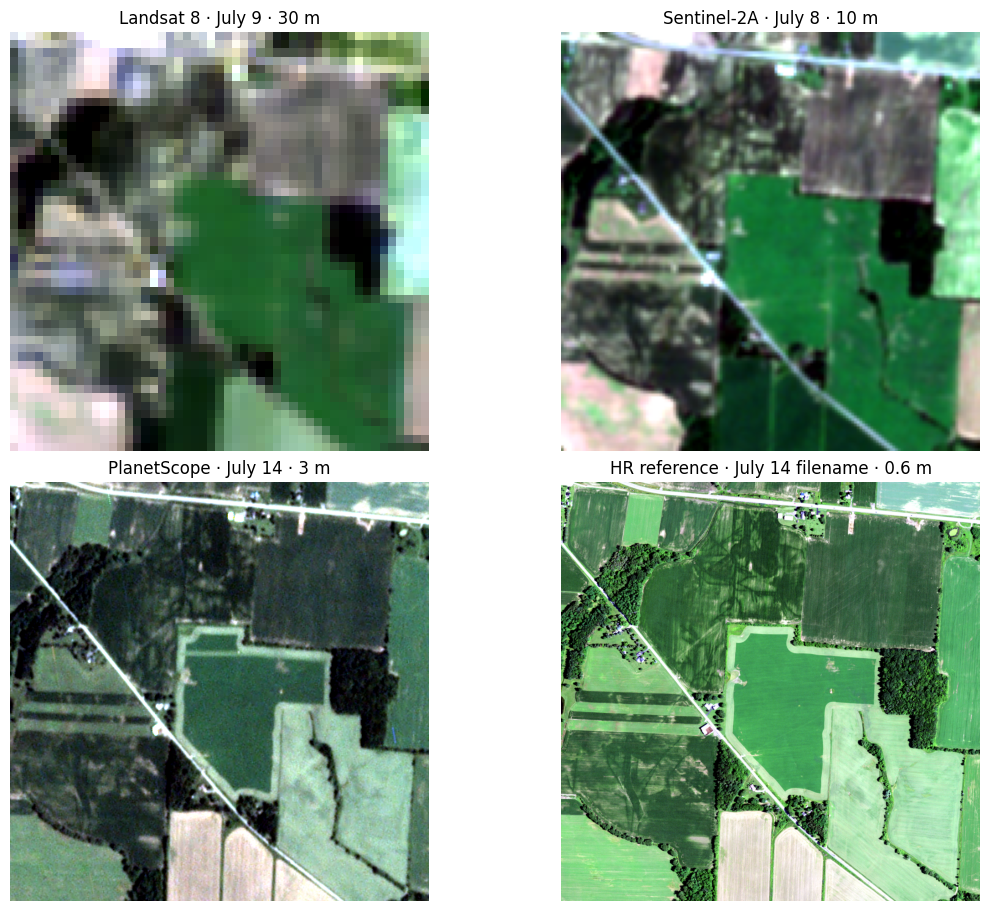

In [6]:
def rgb_stretch(cube, valid, bands=(2, 1, 0), percentiles=(2, 98)):  # contrast-stretched RGB image of a cube
    """Return a display-only independently stretched RGB image."""
    rgb = cube[list(bands)].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for channel in range(3):  # each colour channel
        samples = rgb[..., channel][keep]  # its valid values
        if samples.size == 0:  # nothing to stretch
            raise ValueError("No valid pixels for RGB stretch")  # stop with a clear message
        low, high = np.percentile(samples, percentiles)  # percentile limits
        rgb[..., channel] = np.clip(  # stretch to [0, 1]
            (rgb[..., channel] - low) / max(high - low, 1e-6), 0, 1
        )
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

def fill_nearest(cube, valid):  # fill invalid pixels with the nearest valid value
    """Temporarily fill invalid (band, y, x) values for algorithms requiring finite input."""
    if not valid.any():  # nothing to fill from
        raise ValueError("Cannot fill an image with no valid pixels")  # stop with a clear message
    # row and column of the nearest valid pixel
    rows, cols = distance_transform_edt(~valid, return_distances=False, return_indices=True)
    filled = np.asarray(cube, dtype="float32").copy()  # copy of the cube
    for band in range(filled.shape[0]):  # every band
        filled[band, ~valid] = filled[band, rows[~valid], cols[~valid]]  # copy the nearest valid value
    return filled  # the filled cube

landsat_filled = fill_nearest(landsat_values, landsat_valid)  # Landsat with gaps filled
sentinel_filled = fill_nearest(sentinel_values, sentinel_valid)  # Sentinel-2 with gaps filled
planet_filled = fill_nearest(planet_values, planet_valid)  # PlanetScope with gaps filled
hr_filled = fill_nearest(hr_values, hr_valid)  # HR with gaps filled

fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)  # 2 x 2 panels
views = [  # image, mask and title of each panel
    (landsat_filled, landsat_valid, "Landsat 8 · July 9 · 30 m"),
    (sentinel_filled, sentinel_valid, "Sentinel-2A · July 8 · 10 m"),
    (planet_filled, planet_valid, "PlanetScope · July 14 · 3 m"),
    (hr_filled, valid_planet_hr, "HR reference · July 14 filename · 0.6 m"),
]
for ax, (cube, mask, title) in zip(axes.flat, views):  # every panel
    ax.imshow(rgb_stretch(cube, mask))  # RGB view
    ax.set_title(title)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Landsat 8 → Sentinel-2 (30 m to 10 m)

### Classical baselines

All classical outputs are generated from the 30 m Landsat window and placed on the aligned 10 m Sentinel grid. Nearest, bilinear, bicubic, and Lanczos are interpolation baselines; unsharp masking increases local contrast. Sentinel-2 is reserved as a paired reference for training and held-out evaluation. These operations do not make true 10 m Landsat observations.


In [7]:
landsat_10m_da = {  # interpolation methods from 30 m to the 10 m grid
    "Nearest": sr.upsample(landsat_window, SCALE_LANDSAT, method="nearest"),
    "Bilinear": sr.upsample(landsat_window, SCALE_LANDSAT, method="bilinear"),
    "Bicubic": landsat_10m_grid,
    "Lanczos": sr.upsample(landsat_window, SCALE_LANDSAT, method="lanczos"),
}
landsat_classical = {  # their values as arrays
    name: np.asarray(image.values, dtype="float32")
    for name, image in landsat_10m_da.items()
}
landsat_classical["Unsharp bicubic"] = sr.unsharp_mask(  # mild sharpening of the bicubic result
    landsat_classical["Bicubic"], amount=0.5, sigma=1.0
)
# all have the Sentinel-2 shape
assert all(cube.shape == sentinel_values.shape for cube in landsat_classical.values())
print("30 m → 10 m candidates:", {name: cube.shape for name, cube in landsat_classical.items()})  # their shapes

30 m → 10 m candidates: {'Nearest': (4, 153, 153), 'Bilinear': (4, 153, 153), 'Bicubic': (4, 153, 153), 'Lanczos': (4, 153, 153), 'Unsharp bicubic': (4, 153, 153)}


### Form paired patches and a spatial holdout

Each 6×6 Landsat patch is paired with its corresponding 18×18 Sentinel-2 patch. Only patches that are at least 98% valid in both scenes are kept. Neighboring groups are assigned together to training or validation so adjacent pixels are less likely to leak across the split. This small area is enough to demonstrate the code, but not enough to claim generalization across landscapes.


In [8]:
PATCH_HR_LS = PATCH_LANDSAT * SCALE_LANDSAT  # size of a target patch on the 10 m grid
ls_records = []  # usable Landsat patches: position and validation flag
height, width = landsat_valid.shape  # Landsat window size
for row in range(0, height - PATCH_LANDSAT + 1, PATCH_LANDSAT):  # patch rows
    for col in range(0, width - PATCH_LANDSAT + 1, PATCH_LANDSAT):  # patch columns
        # Landsat validity of the patch
        low_mask = landsat_valid[row:row + PATCH_LANDSAT, col:col + PATCH_LANDSAT]
        r0, c0 = row * SCALE_LANDSAT, col * SCALE_LANDSAT  # matching position on the 10 m grid
        # Sentinel-2 validity of the matching patch
        fine_mask = sentinel_valid[r0:r0 + PATCH_HR_LS, c0:c0 + PATCH_HR_LS]
        if low_mask.mean() >= 0.98 and fine_mask.mean() >= 0.98:  # keep patches at least 98 % valid in both
            block_row, block_col = row // PATCH_LANDSAT, col // PATCH_LANDSAT  # patch row and column number
            # every fourth 2 x 2 block of patches is held out
            validation = ((block_row // 2 + block_col // 2) % 4) == 0
            ls_records.append((row, col, validation))  # store the patch
ls_train = [record for record in ls_records if not record[2]]  # training patches
ls_validation = [record for record in ls_records if record[2]]  # validation patches
if len(ls_train) < 8 or len(ls_validation) < 2:  # too few of either
    # stop with a clear message
    raise RuntimeError(f"Not enough clear Landsat/Sentinel patches: {len(ls_train)} train, "
                       f"{len(ls_validation)} validation")
X_ls = torch.from_numpy(np.stack([  # training inputs: Landsat patches
    landsat_filled[:, r:r + PATCH_LANDSAT, c:c + PATCH_LANDSAT]
    for r, c, _ in ls_train
])).float()
Y_s2 = torch.from_numpy(np.stack([  # training targets: Sentinel-2 patches
    sentinel_filled[:, r * SCALE_LANDSAT:(r + PATCH_LANDSAT) * SCALE_LANDSAT,
                    c * SCALE_LANDSAT:(c + PATCH_LANDSAT) * SCALE_LANDSAT]
    for r, c, _ in ls_train
])).float()
loader_ls = DataLoader(TensorDataset(X_ls, Y_s2), batch_size=8, shuffle=True)  # shuffled batches of 8
print(f"Landsat/Sentinel patch pairs: {len(ls_records)} total; {len(ls_train)} train; "  # patch counts
      f"{len(ls_validation)} held out")
print("Training shapes:", tuple(X_ls.shape), tuple(Y_s2.shape))  # tensor shapes

Landsat/Sentinel patch pairs: 64 total; 48 train; 16 held out
Training shapes: (48, 4, 6, 6) (48, 4, 18, 18)


### Train the Landsat-to-Sentinel CNN

The GeoLattice EDSR-style network takes four Landsat bands and predicts four bands at ×3. Its objective combines L1 reflectance error, spectral-angle loss, and coarse-observation consistency. Sentinel-2 supplies the high-resolution training target and held-out reference. Since the acquisitions are one day apart, the pair is relatively close in time, but differences in point-spread function, bandpass, atmospheric processing, and co-registration remain.


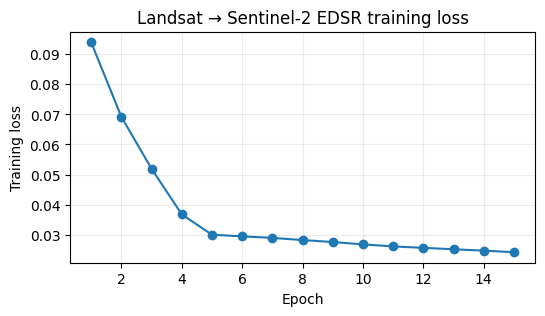

In [9]:
model_landsat = sr.build_sr_model(  # an EDSR network for Landsat -> Sentinel-2
    in_channels=len(BANDS), scale=SCALE_LANDSAT,
    features=24, blocks=3, architecture="edsr",
)
history_landsat = sr.train_super_resolution(  # train it
    model_landsat, loader_ls, epochs=15, lr=1e-4, device=DEVICE,
    sam_weight=0.05, consistency_weight=0.05,
)
fig, ax = plt.subplots(figsize=(6, 3))  # one panel
ax.plot(np.arange(1, len(history_landsat["train_loss"]) + 1),  # training loss per epoch
        history_landsat["train_loss"], marker="o")
ax.set(xlabel="Epoch", ylabel="Training loss",  # labels and title
       title="Landsat → Sentinel-2 EDSR training loss")
ax.grid(alpha=0.25)  # grid
plt.show()  # draw

### Inference and held-out Landsat/Sentinel scoring

Tiled GeoLattice inference predicts the whole Landsat window on the 10 m grid. Metrics use only spatially held-out valid pixels and compare the predictions with Sentinel-2. RMSE is in the input reflectance units, PSNR assumes reflectance [0,1], and SAM measures spectral-vector angle. These metrics quantify agreement with Sentinel-2, not with a known fine-resolution Landsat truth.


In [10]:
landsat_filled_da = landsat_window.copy(data=landsat_filled)  # filled Landsat as a georeferenced DataArray
landsat_cnn_da = sr.predict_super_resolution(  # apply the trained network to the whole window
    model_landsat, landsat_filled_da, tile=64, overlap=12, batch_size=4, device=DEVICE
)
landsat_cnn = np.asarray(landsat_cnn_da.values, dtype="float32")  # the prediction as an array
# classical estimates plus the network
landsat_candidates = {**landsat_classical, "CNN (paired patches)": landsat_cnn}

# scores on held-out patches for either sensor pair
def paired_metrics(prediction, reference, records, valid_mask, patch, scale):
    """Compute RMSE, unit-range PSNR, and SAM over spatially held-out patches."""
    hpatch = round(patch * scale)  # size of a target patch
    estimates, targets = [], []  # pieces of prediction and reference
    for row, col, _ in records:  # every held-out patch
        r0, c0 = round(row * scale), round(col * scale)  # its position on the fine grid
        mask = valid_mask[r0:r0 + hpatch, c0:c0 + hpatch]  # valid pixels of the patch
        if mask.any():  # skip patches without valid pixels
            # the predicted patch, valid pixels only
            estimates.append(prediction[:, r0:r0 + hpatch, c0:c0 + hpatch][:, mask])
            # the reference patch, valid pixels only
            targets.append(reference[:, r0:r0 + hpatch, c0:c0 + hpatch][:, mask])
    if not estimates:  # nothing to score
        raise ValueError("No valid pixels in held-out patches")  # stop with a clear message
    estimate, target = np.concatenate(estimates, axis=1), np.concatenate(targets, axis=1)  # all pixels of both
    rmse = float(np.sqrt(np.mean((estimate - target) ** 2)))  # root-mean-square error
    dot = np.sum(estimate * target, axis=0)  # dot product of the spectra
    norms = np.linalg.norm(estimate, axis=0) * np.linalg.norm(target, axis=0)  # product of their lengths
    sam = np.degrees(np.arccos(np.clip(dot / np.maximum(norms, 1e-8), -1, 1)))  # spectral angle of every pixel
    # RMSE, PSNR and mean spectral angle
    return {"RMSE": rmse, "PSNR (range=1)": float(20 * np.log10(1 / max(rmse, 1e-12))),
            "SAM (degrees)": float(sam.mean())}

landsat_scores = {  # score every Landsat method
    name: paired_metrics(cube, sentinel_values, ls_validation,
                         sentinel_valid, PATCH_LANDSAT, SCALE_LANDSAT)
    for name, cube in landsat_candidates.items()
}
display(xr.Dataset({  # as a table, best first
    metric: xr.DataArray([landsat_scores[name][metric] for name in landsat_scores],
                         dims="method", coords={"method": list(landsat_scores)})
    for metric in next(iter(landsat_scores.values()))
}).to_dataframe().sort_values("RMSE").style.format("{:.4f}"))

,RMSE,PSNR (range=1),SAM (degrees)
method,,,
CNN (paired patches),0.0212,33.4682,2.8935
Unsharp bicubic,0.0246,32.1863,2.7054
Lanczos,0.0246,32.1850,2.6686
Bicubic,0.0247,32.1317,2.7342
Bilinear,0.0252,31.9697,2.8205
Nearest,0.0254,31.9078,2.8331


### Compare the Landsat estimates against Sentinel-2

The Sentinel-2 reference and all Landsat estimates share a display stretch derived from valid Sentinel-2 RGB pixels. This makes the predicted outputs visually comparable with their training reference. Cloud/nodata pixels are masked. Any texture that appears finer than Landsat's native 30 m samples is model-inferred, not directly measured by Landsat.


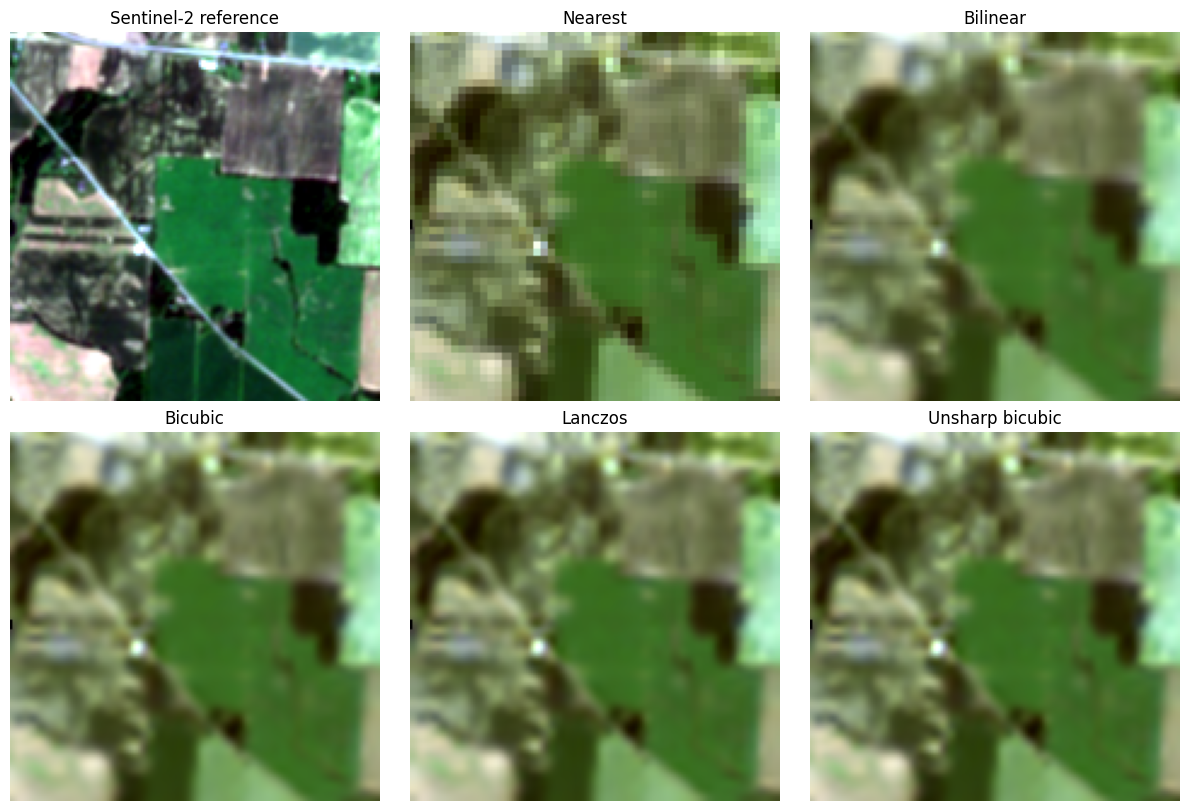

In [11]:
s2_rgb = sentinel_filled[[2, 1, 0]].transpose(1, 2, 0)  # Sentinel-2 RGB, used to fix the display stretch
s2_display_mask = sentinel_valid & np.isfinite(s2_rgb).all(axis=-1)  # its valid pixels
# 2-98 % limits of each channel, shared by all panels
LS_DISPLAY_LIMITS = [np.percentile(s2_rgb[..., i][s2_display_mask], [2, 98])
                     for i in range(3)]

def rgb_landsat_comparison(cube, valid):  # RGB image with the shared stretch
    rgb = cube[[2, 1, 0]].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for i, (low, high) in enumerate(LS_DISPLAY_LIMITS):  # each channel with its limits
        rgb[..., i] = np.clip((rgb[..., i] - low) / max(high - low, 1e-6), 0, 1)  # stretch to [0, 1]
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)  # 2 x 3 panels
# the reference and every Landsat estimate
for ax, name in zip(axes.flat, ["Sentinel-2 reference", *landsat_candidates.keys()]):
    # the image of this panel
    cube = sentinel_filled if name == "Sentinel-2 reference" else landsat_candidates[name]
    ax.imshow(rgb_landsat_comparison(cube, sentinel_valid))  # RGB view
    ax.set_title(name)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## PlanetScope → HR (3 m to 0.6 m), an independent experiment

### Prepare PlanetScope/HR patch pairs and fit training-only calibration

PlanetScope input values are scaled using the explicit 0.0001 assumption. HR pixels are normalized by 255, then averaged in aligned 5×5 blocks to approximate their corresponding 3 m samples. A per-band linear fit maps HR block averages to PlanetScope values using **training patches only**. This reduces an overall offset/scale mismatch, but is not physical atmospheric or spectral harmonization. A spatial block holdout prevents calibration and model training from using the validation patches.


In [12]:
PATCH_HR_PS = PATCH_PLANET * SCALE_PLANET  # size of a target patch on the 0.6 m grid
ps_height, ps_width = planet_valid.shape  # PlanetScope window size
ps_records = []  # usable PlanetScope patches
for row in range(0, ps_height - PATCH_PLANET + 1, PATCH_PLANET):  # patch rows
    for col in range(0, ps_width - PATCH_PLANET + 1, PATCH_PLANET):  # patch columns
        # PlanetScope validity of the patch
        low_mask = planet_valid[row:row + PATCH_PLANET, col:col + PATCH_PLANET]
        r0, c0 = row * SCALE_PLANET, col * SCALE_PLANET  # matching position on the 0.6 m grid
        # validity of the matching 0.6 m patch
        high_mask = valid_planet_hr[r0:r0 + PATCH_HR_PS, c0:c0 + PATCH_HR_PS]
        if low_mask.mean() >= 0.98 and high_mask.mean() >= 0.98:  # keep patches at least 98 % valid in both
            block_row, block_col = row // PATCH_PLANET, col // PATCH_PLANET  # patch row and column number
            # every fifth 2 x 2 block of patches is held out
            validation = ((block_row // 2 + block_col // 2) % 5) == 0
            ps_records.append((row, col, validation))  # store the patch
ps_train = [record for record in ps_records if not record[2]]  # training patches
ps_validation = [record for record in ps_records if record[2]]  # validation patches
if len(ps_train) < 8 or len(ps_validation) < 2:  # too few of either
    # stop with a clear message
    raise RuntimeError(f"Not enough valid PlanetScope/HR patches: {len(ps_train)} train, "
                       f"{len(ps_validation)} validation")

# Average each aligned 5 x 5 block of 0.6 m HR pixels to the 3 m grid.
hr_blocks = hr_filled.reshape(4, ps_height, SCALE_PLANET, ps_width, SCALE_PLANET)
hr_coarse = hr_blocks.mean(axis=(2, 4))  # mean HR value of each 3 m block
train_mask = np.zeros((ps_height, ps_width), dtype=bool)  # mask of the training patches
for row, col, _ in ps_train:  # every training patch
    train_mask[row:row + PATCH_PLANET, col:col + PATCH_PLANET] = True  # mark it
calibration_mask = train_mask & planet_valid  # fit only on valid training pixels
planet_hr_calibration = []  # (slope, intercept) per band
for band in range(len(BANDS)):  # every band
    slope, intercept = np.polyfit(  # fit HR -> PlanetScope reflectance
        hr_coarse[band][calibration_mask], planet_values[band][calibration_mask], 1
    )
    planet_hr_calibration.append((float(slope), float(intercept)))  # store the fit
hr_calibrated = np.asarray([  # the HR image converted to the PlanetScope scale
    hr_filled[b] * planet_hr_calibration[b][0] + planet_hr_calibration[b][1]
    for b in range(len(BANDS))
], dtype="float32")

print(f"PlanetScope/HR patches: {len(ps_records)} total; {len(ps_train)} train; "  # patch counts
      f"{len(ps_validation)} spatial holdout")
print("HR-to-Planet training-only (slope, intercept):")  # heading
for band, coefficients in zip(BANDS, planet_hr_calibration):  # every band
    print(f"  {band}: {coefficients}")  # its slope and intercept

PlanetScope/HR patches: 961 total; 768 train; 193 spatial holdout
HR-to-Planet training-only (slope, intercept):
  blue: (0.14253989598104636, 0.006223867270650143)
  green: (0.13244749000694678, 0.006533150281129151)
  red: (0.13489010598059079, 0.009923471440669615)
  nir: (0.8271936860091486, -0.15514075749209072)


### Train and evaluate PlanetScope-to-HR independently

The second EDSR-style model uses ×5 scale and is trained only on PlanetScope/HR pairs. It is not initialized with or fed the Landsat-derived model output. Held-out scores compare the prediction to the calibrated HR reference and share the same limitations: uncertain HR metadata, residual alignment, spectral mismatch, and a single local scene.


In [13]:
X_ps = torch.from_numpy(np.stack([  # training inputs: PlanetScope patches
    planet_filled[:, r:r + PATCH_PLANET, c:c + PATCH_PLANET]
    for r, c, _ in ps_train
])).float()
Y_hr = torch.from_numpy(np.stack([  # training targets: calibrated HR patches
    hr_calibrated[:, r * SCALE_PLANET:(r + PATCH_PLANET) * SCALE_PLANET,
                  c * SCALE_PLANET:(c + PATCH_PLANET) * SCALE_PLANET]
    for r, c, _ in ps_train
])).float()
loader_ps = DataLoader(TensorDataset(X_ps, Y_hr), batch_size=8, shuffle=True)  # shuffled batches of 8
model_planet = sr.build_sr_model(  # an EDSR network for PlanetScope -> 0.6 m
    in_channels=len(BANDS), scale=SCALE_PLANET,
    features=24, blocks=3, architecture="edsr",
)
history_planet = sr.train_super_resolution(  # train it
    model_planet, loader_ps, epochs=15, lr=1e-4, device=DEVICE,
    sam_weight=0.05, consistency_weight=0.05,
)
planet_cnn_da = sr.predict_super_resolution(  # apply it to the whole PlanetScope window
    model_planet, planet_low.copy(data=planet_filled),
    tile=64, overlap=12, batch_size=4, device=DEVICE,
)
planet_cnn = np.asarray(planet_cnn_da.values, dtype="float32")  # the prediction as an array
planet_candidates = {  # interpolation methods to the 0.6 m grid
    "Nearest": sr.upsample(planet_low, SCALE_PLANET, method="nearest").values,
    "Bilinear": sr.upsample(planet_low, SCALE_PLANET, method="bilinear").values,
    "Bicubic": sr.upsample(planet_low, SCALE_PLANET, method="bicubic").values,
    "Lanczos": sr.upsample(planet_low, SCALE_PLANET, method="lanczos").values,
}
# their values as float arrays
planet_candidates = {k: np.asarray(v, dtype="float32") for k, v in planet_candidates.items()}
planet_candidates["Unsharp bicubic"] = sr.unsharp_mask(  # mild sharpening of the bicubic result
    planet_candidates["Bicubic"], amount=0.5, sigma=1.0
)
planet_candidates["CNN (paired patches)"] = planet_cnn  # add the network's result
planet_scores = {  # score every PlanetScope method
    name: paired_metrics(cube, hr_calibrated, ps_validation,
                         valid_planet_hr, PATCH_PLANET, SCALE_PLANET)
    for name, cube in planet_candidates.items()
}
print("PlanetScope-to-HR training loss:", f"{history_planet['train_loss'][-1]:.5f}")  # final training loss
display(xr.Dataset({  # the scores as a table, best first
    metric: xr.DataArray([planet_scores[name][metric] for name in planet_scores],
                         dims="method", coords={"method": list(planet_scores)})
    for metric in next(iter(planet_scores.values()))
}).to_dataframe().sort_values("RMSE").style.format("{:.4f}"))

PlanetScope-to-HR training loss: 0.00947


,RMSE,PSNR (range=1),SAM (degrees)
method,,,
CNN (paired patches),0.0203,33.8419,1.1758
Bilinear,0.0256,31.8252,1.6599
Bicubic,0.0258,31.7653,1.6744
Unsharp bicubic,0.0258,31.7567,1.6770
Nearest,0.0258,31.7526,1.6882
Lanczos,0.0260,31.7152,1.6905


### Compare PlanetScope estimates with the calibrated HR target

This view uses a common RGB stretch derived from the calibrated high-resolution reference, appropriate for comparing this experiment's outputs with its training target. It is separate from the independent-stretch scene overview. The calibration is a training-only affine fit, so display colors and metrics should be treated as relative diagnostics rather than absolute reflectance.


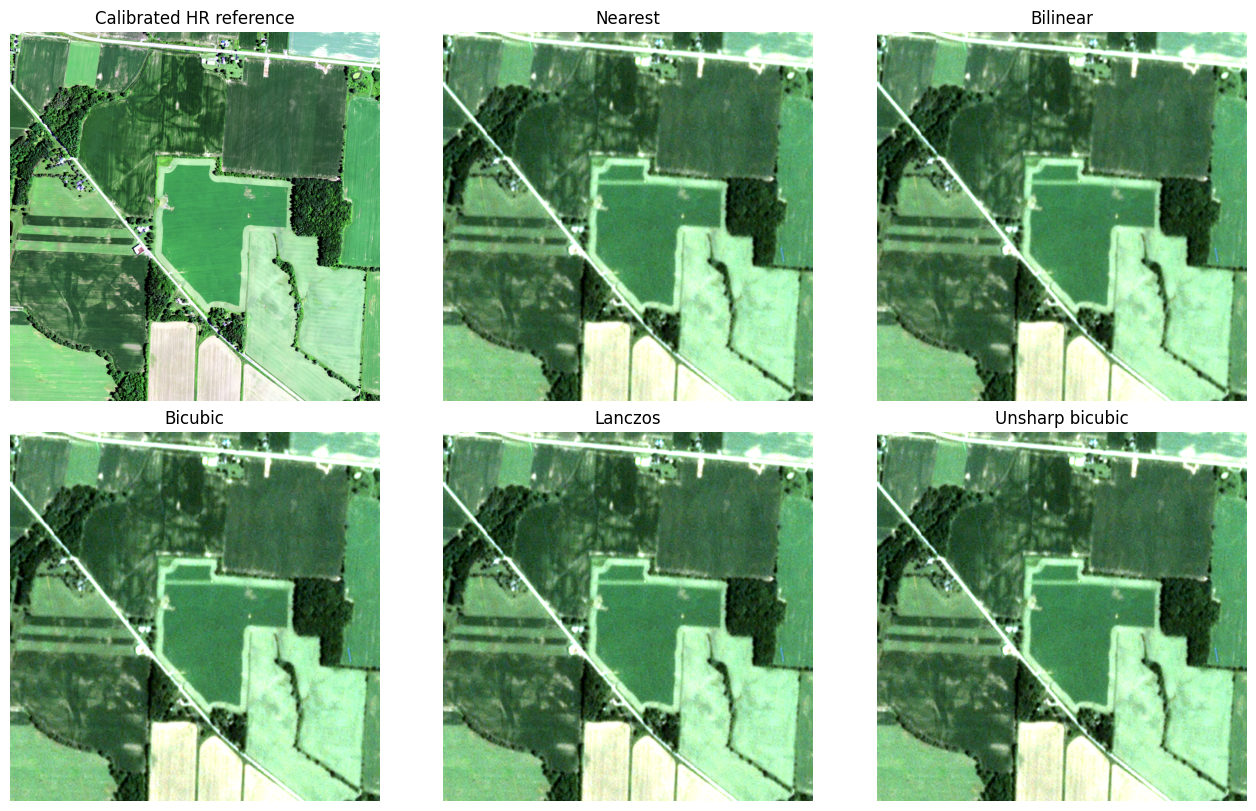

In [14]:
hr_rgb_cal = hr_calibrated[[2, 1, 0]].transpose(1, 2, 0)  # calibrated HR RGB, used to fix the display stretch
hr_rgb_mask = valid_planet_hr & np.isfinite(hr_rgb_cal).all(axis=-1)  # its valid pixels
# 2-98 % limits of each channel, shared by all panels
PS_DISPLAY_LIMITS = [np.percentile(hr_rgb_cal[..., i][hr_rgb_mask], [2, 98])
                     for i in range(3)]

def rgb_planet_comparison(cube, valid):  # RGB image with the shared stretch
    rgb = cube[[2, 1, 0]].transpose(1, 2, 0).copy()  # bands red, green, blue -> (rows, cols, 3)
    keep = valid & np.isfinite(rgb).all(axis=-1)  # valid pixels
    for i, (low, high) in enumerate(PS_DISPLAY_LIMITS):  # each channel with its limits
        rgb[..., i] = np.clip((rgb[..., i] - low) / max(high - low, 1e-6), 0, 1)  # stretch to [0, 1]
    rgb[~keep] = 0  # invalid pixels in black
    return rgb  # the RGB image

plot_order = ["Calibrated HR reference", *planet_candidates.keys()]  # panel order
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)  # 2 x 3 panels
for ax, name in zip(axes.flat, plot_order):  # every panel
    # the image of this panel
    cube = hr_calibrated if name == "Calibrated HR reference" else planet_candidates[name]
    ax.imshow(rgb_planet_comparison(cube, valid_planet_hr))  # RGB view
    ax.set_title(name)  # title
    ax.set_axis_off()  # no axes
plt.show()  # draw

## Export both independent experiments

### Write pair-specific outputs and preserve their grids

Landsat-derived products use the aligned Sentinel-2 10 m output grid; PlanetScope-derived products use the matching HR 0.6 m grid. Each result gets its own directory to make clear that these are two separate model stages and products. Invalid pixels are restored to NaN before `rs.write` creates COGs. Product tags record the source and interpretation so the fine output grid is not confused with native sensor resolution.


In [15]:
landsat_output_dir = OUTPUT_DIR / "landsat_to_sentinel2_10m"  # output folder for the Landsat results
planet_output_dir = OUTPUT_DIR / "planetscope_to_hr_06m"  # output folder for the PlanetScope results
landsat_output_dir.mkdir(parents=True, exist_ok=True)  # create it
planet_output_dir.mkdir(parents=True, exist_ok=True)  # create it

valid_landsat_output = np.repeat(  # Landsat validity repeated onto the 10 m grid
    np.repeat(landsat_valid, SCALE_LANDSAT, axis=0), SCALE_LANDSAT, axis=1
) & sentinel_valid

# save one estimate as a Cloud-Optimised GeoTIFF
def write_candidate(cube, template, valid, out_path, attributes):
    values = np.where(valid[None, :, :], cube, np.nan).astype("float32")  # invalid pixels -> NaN
    # the template with these values and NaN as no-data
    result = template.copy(data=values).rio.write_nodata(np.nan)
    result.attrs = attributes  # what the file contains
    rs.write(result, out_path, cog=True)  # write it

for name, cube in landsat_candidates.items():  # every Landsat estimate
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "")  # a file-safe name
    write_candidate(  # save it
        cube, landsat_10m_grid, valid_landsat_output,
        landsat_output_dir / f"{filename}.tif",
        {"method": name, "input_scene": landsat_metadata["scene_id"],
         "reference_scene": sentinel_metadata["scene_id"],
         "interpretation": "10 m estimate; not native Landsat detail"},
    )
for name, cube in planet_candidates.items():  # every PlanetScope estimate
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "")  # a file-safe name
    write_candidate(  # save it
        cube, planet_60cm_grid, valid_planet_hr,
        planet_output_dir / f"{filename}.tif",
        {"method": name, "input_scene": planet_item["id"],
         "reference_file": HR_PATH.name,
         "planet_scale_assumption": PLANET_DN_TO_REFLECTANCE,
         "hr_scale_assumption": HR_DN_TO_UNIT_RANGE,
         "interpretation": "0.6 m estimate; not native PlanetScope detail"},
    )
print("Landsat → Sentinel outputs:", landsat_output_dir)  # Landsat output folder
print("PlanetScope → HR outputs:", planet_output_dir)  # PlanetScope output folder

Landsat → Sentinel outputs: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_all_sensors/landsat_to_sentinel2_10m
PlanetScope → HR outputs: /media/zia207/SSD/GitHub/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_08_image_super_resolution/data/super_resolution_outputs_all_sensors/planetscope_to_hr_06m


## Interpretation

- This notebook **does not** create a serial Landsat → Sentinel → PlanetScope → HR prediction chain. It trains and tests two direct sensor pairs to avoid compounding errors: Landsat 30→10 m Sentinel-2 and PlanetScope 3→0.6 m HR.
- The Landsat model's score answers: how well does its estimate match held-out Sentinel-2 for this near-coincident scene? It does not show that Sentinel texture is native Landsat information.
- The PlanetScope model's score answers: how well does its estimate match held-out calibrated HR pixels in this local window? HR metadata and radiometry remain less certain than for the satellite products.
- The two pairs have different bandpasses, atmospheric correction, date offsets, and training distributions. Do not compare their RMSE values directly as if they were the same task.
- Sentinel-2 visible/NIR bands are native 10 m; its SWIR bands were deliberately omitted because they are native 20 m. PlanetScope reports 3.6 m GSD despite 3 m output pixels; HR pixels are 0.6 m.
- All fine-grid outputs are estimates. Check registration, scene masks, independent dates, and downstream classification/area statistics before operational use.

For a rigorous four-sensor product, retrieve verified HR sensor metadata, establish sub-pixel co-registration and reflectance harmonization, repeat on multiple regions/dates, and compare task-level outcomes as well as image metrics.
